# Fig. 1 — axion-active phonons in the two materials (paper `draft/main_draft.tex`, `fig:overview`)

Run all; the last cell writes `paper/figures/fig1.pdf` (+ `.png`). Nothing here is computed: positions and moments come
from the base SCF inputs, the axion-charge directions from the displaced Q = 0.01 Å inputs of each Γ₂⁻ / T₂⁻ basis
pattern, and their sizes z_κ from the paper tables (`tab:yio-charges`, `tab:mbt-charges`; Eq. `zkappa`,
Z^θ_κ = z_κ v̂_κ). Update `YIO_Z` / `MBT_Z` when those change.

| panel | content |
|---|---|
| (a) | Y₂Ir₂O₇ seen along [001], the −4 axis of the cluster: one Ir₄ tetrahedron (a square in projection; moments all-out on this one, all-in on its neighbours), the six O(48f) on its edges (two at the centre, one behind the other: ⊗ = away from the viewer), and the eight Y around it (the other four Y project onto the Ir and are left out, `YIO_Y`). Black: moments; red: Z^θ_κ (arrow scale `ARROW_YIO`, bar 0.005 rad/Å). On Ir, Z^θ is antiparallel to the moment |
| (b) | MnBi₂Te₄ in the style of Fig. 7 (a): two septuple layers (vdW gap to vdW gap) seen along a hexagonal a axis, MnTe₆ / BiTe₆ octahedra, Mn moments ±c, Z^θ_κ along c (bar 1 rad/Å, 160× shorter per rad/Å than (a)). On Mn, Z^θ is antiparallel to the moment; every site of one layer has the opposite Z^θ to its partner in the other |
| (c) | schematic θ(Q): leaves 0 (Y₂Ir₂O₇) and π (MnBi₂Te₄) linearly, slope ∂θ/∂Q (not to scale) |

Colours: the Fig. 7 palette, by role, also used for the PDOS of Fig. 3: magnetic ion (Ir, Mn) purple, the other cation
(Y, Bi) blue, anion orange (O(48f), outer Te1; inner Te2 yellow). Axion-charge arrows in Fig. 7's arrow red, moments black.


In [1]:
# ---- settings
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyArrowPatch, Polygon, Rectangle
from scipy.spatial import ConvexHull

ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
Q = 0.01                                                    # Å, amplitude of the displaced inputs below
YIO_BASE = DATA / "Y2Ir2O7/dft/base/scf/out/Y2Ir2O7.scf.in"                 # positions (Å), AIAO angles; SCF 213998
YIO_PATTERNS = {"Y": DATA / "Y2Ir2O7/dft/GM2-_p1_Q0.01/scf/out/Y2Ir2O7.scf.in",    # pattern i moves this orbit
                "Ir": DATA / "Y2Ir2O7/dft/GM2-_p2_Q0.01/scf/out/Y2Ir2O7.scf.in",
                "O": DATA / "Y2Ir2O7/dft/GM2-_p3_Q0.01/scf/out/Y2Ir2O7.scf.in"}    # O(48f)
YIO_Z = {"Y": -0.0025, "Ir": +0.0079, "O": +0.0053}        # z_kappa (rad/Å), paper Table yio-charges (Q -> 0, nk 10)
MBT_BASE = DATA / "MnBi2Te4/dft/base/scf/out/MnBi2Te4.scf.in"               # positions (Å), Mn1 up / Mn2 down; SCF 214290
MBT_PATTERNS = {"Mn": DATA / "MnBi2Te4/dft/T2-_p1_Q0.01/scf/out/MnBi2Te4.scf.in",
                "Bi": DATA / "MnBi2Te4/dft/T2-_p2_Q0.01/scf/out/MnBi2Te4.scf.in",
                "Te1": DATA / "MnBi2Te4/dft/T2-_p3_Q0.01/scf/out/MnBi2Te4.scf.in",  # outer Te (van der Waals gap)
                "Te2": DATA / "MnBi2Te4/dft/T2-_p4_Q0.01/scf/out/MnBi2Te4.scf.in"}  # inner Te (bonded to Mn)
MBT_Z = {"Mn": -0.98, "Bi": +0.95, "Te1": +1.60, "Te2": -1.14}  # z_kappa (rad/Å), paper Table mbt-charges
# drawing
VIEW_YIO, UP_YIO = (0, 0, 1), (0, 1, 0)   # YIO: viewer along [001] (the cluster's -4 axis), screen up along [010]
YIO_Y = "ring"                      # "ring": the 8 Y around the square | "all": also the 4 that project onto the Ir | "none"
ARROW_YIO = 190.0                   # Å of arrow per rad/Å (YIO Z^theta)
ARROW_MBT = 1.25                    # Å of arrow per rad/Å (MBT Z^theta)
MOMENT_LEN = {"YIO": 1.5, "MBT": 2.0}   # Å, drawn length of a magnetic moment
SCALE_BAR = {"YIO": 0.005, "MBT": 1.0}  # rad/Å
ALONG_VIEW = 0.35                   # a vector whose projection is shorter than this fraction is drawn as ⊙ / ⊗
MBT_PERIODS = 2                     # in-plane periods shown in the side view
ZLO, ZHI = -6.6, 20.3               # Å from Mn1, MBT window (as Fig. 7)
COLORS = {"Ir": "#7b3294", "Mn": "#7b3294",                 # magnetic ion       (Fig. 7 palette)
          "Y": "#2b6cb0", "Bi": "#2b6cb0",                  # other cation
          "O": "#d9821e", "Te1": "#d9821e", "Te2": "#f7dc6f"}   # anion (MBT outer / inner Te)
RADII = {"Ir": 0.40, "Y": 0.36, "O": 0.26, "Mn": 0.36, "Bi": 0.48, "Te1": 0.44, "Te2": 0.44}   # drawn radius, Å
ZTH_COLOR = "#c0392b"               # axion-charge arrows (the arrow colour of Fig. 7)
MOMENT_COLOR = "black"
FIGSIZE = (7.0, 3.0)                # inches; 7.0 = two-column (figure*) width
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig1.pdf"   # (+ .png); or None
# ---------------


In [2]:
# ---- read the structures: positions, magnetic moments, and Z^theta_kappa = z_kappa * (unit pattern displacement)
def read_pw_input(path):
    """cell (rows, Å), atom labels, positions (Å), {species: (angle1, angle2)} of the magnetic species, from a pw.x
    input with CELL_PARAMETERS and ATOMIC_POSITIONS in angstrom."""
    text = Path(path).read_text()
    lines = text.splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith("CELL_PARAMETERS"))
    assert "angstrom" in lines[i].lower(), lines[i]
    cell = np.array([[float(x) for x in lines[i + j].split()[:3]] for j in (1, 2, 3)])
    i = next(k for k, l in enumerate(lines) if l.startswith("ATOMIC_POSITIONS"))
    assert "angstrom" in lines[i].lower(), lines[i]
    labels, pos = [], []
    for line in lines[i + 1:]:
        s = line.split()
        if len(s) < 4 or not re.match(r"[A-Z][a-z]?\d*$", s[0]):
            break
        labels.append(s[0]); pos.append([float(x) for x in s[1:4]])
    i = next(k for k, l in enumerate(lines) if l.startswith("ATOMIC_SPECIES"))
    species = []
    for line in lines[i + 1:]:
        s = line.split()
        if not s or not re.match(r"[A-Z][a-z]?\d*$", s[0]):
            break
        species.append(s[0])
    angles = {}
    for n, sp in enumerate(species, 1):
        m = re.search(rf"starting_magnetization\({n}\)\s*=\s*([-\d.]+)", text)
        if m and float(m.group(1)) != 0:
            a1 = re.search(rf"angle1\({n}\)\s*=\s*([-\d.]+)", text)
            a2 = re.search(rf"angle2\({n}\)\s*=\s*([-\d.]+)", text)
            angles[sp] = (float(a1.group(1)) if a1 else 0.0, float(a2.group(1)) if a2 else 0.0)
    return cell, labels, np.array(pos), angles


def element(label):
    return re.match(r"[A-Z][a-z]?", label).group(0)


def unit_from_angles(a1, a2):                               # QE: angle1 from z, angle2 azimuth (degrees)
    t, p = np.radians(a1), np.radians(a2)
    return np.array([np.sin(t) * np.cos(p), np.sin(t) * np.sin(p), np.cos(t)])


def pattern_directions(base, patterns):
    """{atom index: (pattern name, unit displacement)} from (displaced - base) / Q; the patterns move disjoint atoms."""
    _, _, p0, _ = read_pw_input(base)
    out = {}
    for name, path in patterns.items():
        _, _, p, _ = read_pw_input(path)
        d = (p - p0) / Q
        for i in np.flatnonzero(np.linalg.norm(d, axis=1) > 1e-6):
            assert i not in out, f"atom {i} moved by two patterns"
            out[i] = (name, d[i] / np.linalg.norm(d[i]))
    return out


def screen(view, up):
    """rows: screen x, screen y, towards the viewer."""
    v = np.asarray(view, float); v /= np.linalg.norm(v)
    u = np.asarray(up, float); u = u - (u @ v) * v; u /= np.linalg.norm(u)
    return np.array([np.cross(u, v), u, v])


# ---- Y2Ir2O7: one Ir4 tetrahedron, the six O(48f) on its edges, the Y around it
cell, labels, pos, angles = read_pw_input(YIO_BASE)
dirs = pattern_directions(YIO_BASE, YIO_PATTERNS)
a_cub = np.linalg.norm(cell[0]) * np.sqrt(2)                # cubic lattice constant (fcc primitive rows)
centre = pos[labels.index("Ir1")] + np.full(3, a_cub / 8)   # centre of the Ir4 tetrahedron with Ir1 at a corner
R_yio = screen(VIEW_YIO, UP_YIO)
shifts = np.array(np.meshgrid(*[range(-2, 3)] * 3)).reshape(3, -1).T @ cell
yio = []
for i, (lab, x) in enumerate(zip(labels, pos)):
    el = element(lab)
    for s in shifts:
        r = x + s - centre
        d = np.linalg.norm(r)
        if (el in ("Ir", "O") and d < 2.3) or (el == "Y" and YIO_Y != "none" and d < 4.3):
            name, v = dirs.get(i, (None, None))
            yio.append(dict(site=el, r=r, moment=unit_from_angles(*angles[lab]) if lab in angles else None,
                            Z=YIO_Z[name] * v if name else None))
if YIO_Y == "ring":                                         # drop the Y that sit in front of / behind an Ir on screen
    ir_xy = [(R_yio @ t["r"])[:2] for t in yio if t["site"] == "Ir"]
    yio = [t for t in yio if t["site"] != "Y" or min(np.linalg.norm((R_yio @ t["r"])[:2] - p) for p in ir_xy) > 0.5]
print("Y2Ir2O7 cluster:", {e: sum(t["site"] == e for t in yio) for e in ("Ir", "O", "Y")})
for t in yio:                                               # outward = away from the tetrahedron centre
    out = t["r"] / np.linalg.norm(t["r"])
    m = f"moment·r̂ {t['moment'] @ out:+.2f}, " if t["moment"] is not None else ""
    print(f"  {t['site']:2s} at {np.linalg.norm(t['r']):.2f} Å: {m}Z·r̂/|Z| {t['Z'] @ out / np.linalg.norm(t['Z']):+.2f}")

# ---- MnBi2Te4: two septuple layers (vdW gap to vdW gap) seen along x, one in-plane period in depth
cell_m, labels_m, pos_m, angles_m = read_pw_input(MBT_BASE)
dirs_m = pattern_directions(MBT_BASE, MBT_PATTERNS)
mn1 = pos_m[labels_m.index("Mn1")]
a_in = np.linalg.norm(cell_m[0] - cell_m[2])                # in-plane lattice constant (rows 0 and 2 differ along x)
period = a_in * np.sqrt(3) / 2                              # repeat along the screen axis y
basis = []
for i, (lab, x) in enumerate(zip(labels_m, pos_m)):
    name, v = dirs_m.get(i, (None, None))
    assert name, f"atom {i} ({lab}) is in no pattern"       # every MnBi2Te4 atom carries a T2- component
    basis.append(dict(site=name, r=x - mn1, moment=unit_from_angles(*angles_m[lab]) if lab in angles_m else None,
                      Z=MBT_Z[name] * v))
n = np.array(np.meshgrid(*[range(-4, 5)] * 3, indexing="ij")).reshape(3, -1).T @ cell_m
mbt_all = [dict(t, r=t["r"] + s) for s in n for t in basis]
mbt_all = [t for t in mbt_all if ZLO - 4 < t["r"][2] < ZHI + 4 and -5 < t["r"][1] < MBT_PERIODS * period + 5
           and -4.5 < t["r"][0] < a_in + 4.5]
mbt = [t for t in mbt_all if -0.01 <= t["r"][0] < a_in - 0.01 and -0.6 < t["r"][1] < MBT_PERIODS * period + 0.6
       and ZLO - 0.6 < t["r"][2] < ZHI + 0.6]
print("MnBi2Te4 sites (z from Mn1, Å):", sorted({(t["site"], round(t["r"][2], 2)) for t in basis}, key=lambda p: p[1]))


Y2Ir2O7 cluster: {'Ir': 4, 'O': 6, 'Y': 8}
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Y  at 4.22 Å: Z·r̂/|Z| -0.17
  Ir at 2.21 Å: moment·r̂ +1.00, Z·r̂/|Z| -1.00
  Ir at 2.21 Å: moment·r̂ +1.00, Z·r̂/|Z| -1.00
  Ir at 2.21 Å: moment·r̂ +1.00, Z·r̂/|Z| -1.00
  Ir at 2.21 Å: moment·r̂ +1.00, Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
  O  at 2.17 Å: Z·r̂/|Z| -1.00
MnBi2Te4 sites (z from Mn1, Å): [('Mn', np.float64(0.0)), ('Te1', np.float64(5.46)), ('Te2', np.float64(12.03)), ('Bi', np.float64(17.39)), ('Bi', np.float64(23.54)), ('Te2', np.float64(28.89)), ('Te1', np.float64(35.47)), ('Mn', np.float64(40.93)), ('Te1', np.float64(46.38)), ('Te2', np.float64(52.96)), ('Bi', np.float64(58.32))

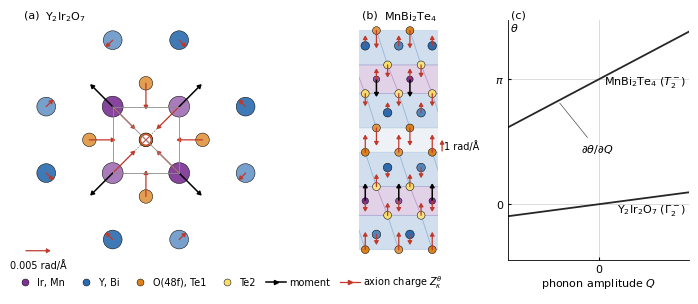

In [3]:
# ---- draw
def arrow(ax, p, d, color, lw, z):
    p, d = np.asarray(p, float), np.asarray(d, float)
    ax.add_patch(FancyArrowPatch(p, p + d, arrowstyle="-|>,head_length=2.2,head_width=1.3", lw=lw, color=color,
                                 shrinkA=0, shrinkB=0, zorder=z))


def vector(ax, xy, vec3, color, lw, z):
    """a 3D vector at xy, drawn as an arrow, or as ⊙ / ⊗ when it points mostly along the viewing direction."""
    if np.hypot(*vec3[:2]) >= ALONG_VIEW * np.linalg.norm(vec3):
        arrow(ax, xy, vec3[:2], color, lw, z)
    else:
        ax.add_patch(Circle(xy, 0.2, fc="white", ec=color, lw=0.8 * lw, zorder=z))
        if vec3[2] > 0:                                     # towards the viewer
            ax.add_patch(Circle(xy, 0.06, fc=color, ec="none", zorder=z + 0.001))
        else:
            for sx in (1, -1):
                ax.plot([xy[0] - 0.13, xy[0] + 0.13], [xy[1] - 0.13 * sx, xy[1] + 0.13 * sx], color=color,
                        lw=0.8 * lw, zorder=z + 0.001, solid_capstyle="butt")


def atom(ax, xy, site, fade, z):
    c = np.array(to_rgb(COLORS[site])) * (1 - fade) + fade  # fade toward white with depth
    ax.add_patch(Circle(xy, RADII[site], fc=c, ec="k", lw=0.35, zorder=z))


def scale_bar(ax, x, y, length_A, text, vertical=False):
    d = (0, length_A) if vertical else (length_A, 0)
    arrow(ax, (x, y), d, ZTH_COLOR, 0.9, 60)
    ax.patches[-1].set_clip_on(False)
    ax.text(x + (0.25 if vertical else length_A / 2), y + (length_A / 2 if vertical else -0.35), text,
            ha="left" if vertical else "center", va="center" if vertical else "top", fontsize=FONT_SIZE - 1, clip_on=False)


plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6, "mathtext.fontset": "dejavusans"})
fig = plt.figure(figsize=FIGSIZE)
gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 0.62, 0.85], wspace=0.22, left=0.005, right=0.985, bottom=0.13, top=0.93)
ax_y, ax_m, ax_t = (fig.add_subplot(gs[0, k]) for k in range(3))

# (a) Y2Ir2O7, projected along VIEW_YIO; back to front, each atom followed by its moment and axion charge
s = np.array([R_yio @ t["r"] for t in yio])
lo, hi = s[:, 2].min(), s[:, 2].max()
irs = [k for k, t in enumerate(yio) if t["site"] == "Ir"]
for p in irs:                                               # tetrahedron edges: the back ones dashed
    for q in irs:
        if p < q:
            back = (s[p, 2] + s[q, 2]) / 2 < -0.5
            ax_y.plot(s[[p, q], 0], s[[p, q], 1], color="0.55", lw=0.6, ls=(0, (2, 1.5)) if back else "-",
                      zorder=1 if back else 25)
for k in np.argsort(s[:, 2]):
    t, z = yio[k], 10 + 10 * (s[k, 2] - lo) / (hi - lo)
    atom(ax_y, s[k, :2], t["site"], 0.45 * (hi - s[k, 2]) / (hi - lo), z)
    if t["moment"] is not None:
        vector(ax_y, s[k, :2], R_yio @ (MOMENT_LEN["YIO"] * t["moment"]), MOMENT_COLOR, 1.1, z + 0.02)
    vector(ax_y, s[k, :2], R_yio @ (ARROW_YIO * t["Z"]), ZTH_COLOR, 0.9, z + 0.01)
ax_y.set_aspect("equal"); ax_y.axis("off")
ax_y.set_xlim(-4.8, 4.8); ax_y.set_ylim(-4.6, 4.6)
scale_bar(ax_y, -4.6, -4.25, ARROW_YIO * SCALE_BAR["YIO"], f"{SCALE_BAR['YIO']:g} rad/Å")

# (b) MnBi2Te4 side view (as Fig. 7 a): MnTe6 / BiTe6 octahedra, depth fade, moments and axion charges along c
ax_m.axhspan(5.46, 8.18, color="#eef2f6", zorder=0, lw=0)
te_all = np.array([t["r"] for t in mbt_all if t["site"].startswith("Te")])
for t in sorted([t for t in mbt_all if t["site"] in ("Mn", "Bi") and -0.01 <= t["r"][0] < a_in - 0.01
                 and -3 < t["r"][1] < MBT_PERIODS * period + 3 and ZLO - 3 < t["r"][2] < ZHI + 3],
                key=lambda t: -t["r"][0]):
    d = np.linalg.norm(te_all - t["r"], axis=1)
    nb = te_all[(d > 0.1) & (d < 3.5)][:, 1:]
    ax_m.add_patch(Polygon(nb[ConvexHull(nb).vertices], closed=True, fc=COLORS[t["site"]], alpha=0.22,
                           ec=COLORS[t["site"]], lw=0.5, zorder=2))
for t in sorted(mbt, key=lambda t: -t["r"][0]):             # viewer at -x
    xy, z = np.array([t["r"][1], t["r"][2]]), 10 + a_in - t["r"][0]
    atom(ax_m, xy, t["site"], 0.35 * t["r"][0] / a_in, z)
    to_screen = lambda v: np.array([v[1], v[2], -v[0]])
    if t["moment"] is not None:
        vector(ax_m, xy, to_screen(MOMENT_LEN["MBT"] * t["moment"]), MOMENT_COLOR, 1.1, 40)
    vector(ax_m, xy, to_screen(ARROW_MBT * t["Z"]), ZTH_COLOR, 0.9, 41)
ax_m.set(xlim=(-0.7, MBT_PERIODS * period + 0.7), ylim=(ZLO, ZHI), aspect="equal")   # the slab; the bar sits outside
ax_m.axis("off")
scale_bar(ax_m, MBT_PERIODS * period + 1.1, 5.6, ARROW_MBT * SCALE_BAR["MBT"], f"{SCALE_BAR['MBT']:g} rad/Å", vertical=True)

# (c) schematic theta(Q)
qq = np.array([-1.0, 1.0])
for v in (0, np.pi):
    ax_t.axhline(v, color="0.8", lw=0.5, zorder=0)
ax_t.axvline(0, color="0.8", lw=0.5, zorder=0)
ax_t.plot(qq, 0.3 * qq, color="0.15", lw=1.3)
ax_t.plot(qq, np.pi + 1.2 * qq, color="0.15", lw=1.3)
ax_t.set(xlim=(-1, 1), ylim=(-1.4, np.pi + 1.5), xticks=[0], xticklabels=["0"], yticks=[0, np.pi],
         yticklabels=["0", r"$\pi$"])
ax_t.set_xlabel(r"phonon amplitude $Q$", labelpad=1)
ax_t.text(-0.98, np.pi + 1.45, r"$\theta$", ha="left", va="top")
ax_t.text(0.97, 0.3 * 0.97 - 0.25, r"Y$_2$Ir$_2$O$_7$ ($\Gamma_2^-$)", ha="right", va="top")
ax_t.text(0.97, np.pi + 1.2 * 0.6 - 0.6, r"MnBi$_2$Te$_4$ ($T_2^-$)", ha="right", va="top")
ax_t.annotate(r"$\partial\theta/\partial Q$", xy=(-0.45, np.pi - 1.2 * 0.45), xytext=(-0.2, np.pi - 1.75),
              arrowprops=dict(arrowstyle="-", lw=0.5, color="0.3"), ha="left", va="center")
for side in ("top", "right"):
    ax_t.spines[side].set_visible(False)
ax_t.tick_params(direction="in", length=2)

for ax, label, title in ((ax_y, "(a)", r"Y$_2$Ir$_2$O$_7$"), (ax_m, "(b)", r"MnBi$_2$Te$_4$"), (ax_t, "(c)", "")):
    fig.text(ax.get_position().x0 + 0.004, 0.965, label, ha="left", va="top")
    if title:
        fig.text(ax.get_position().x0 + 0.035, 0.965, title, ha="left", va="top")

dot = lambda c, text: Line2D([], [], marker="o", ls="", ms=5, mfc=c, mec="k", mew=0.35, label=text)
handles = [dot(COLORS["Ir"], "Ir, Mn"), dot(COLORS["Y"], "Y, Bi"), dot(COLORS["O"], "O(48f), Te1"), dot(COLORS["Te2"], "Te2"),
           Line2D([], [], color=MOMENT_COLOR, lw=1.1, marker=">", ms=3, markevery=[1], label="moment"),
           Line2D([], [], color=ZTH_COLOR, lw=0.9, marker=">", ms=3, markevery=[1], label=r"axion charge $Z^\theta_\kappa$")]
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.01, 0.0), ncol=6, frameon=False, fontsize=FONT_SIZE - 1,
           handletextpad=0.3, columnspacing=1.1)
if SAVE_FIG:
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()
